# Modelado Predictivo: Clasificación con K-Nearest Neighbors (KNN)
**Proyecto:** Clasificador de Salud Fetal (Dataset Cardiotocography - UCI)

**Contexto:** Este notebook aplica el clasificador **KNN** del archivo `Knn.py` para predecir la categoría `NSP` a partir de los datos cardiotocográficos. El algoritmo asigna una clase según la mayoría de los **k vecinos más cercanos**, utilizando distancia euclidiana.

### Objetivos del Modelado

1. **Organización de datos:** Separar las características y la variable objetivo, con **80% para entrenamiento y 20% para prueba** (`seed=42`).
2. **Entrenamiento de KNN:** Estandarizar las características y seleccionar el valor de **k** mediante validación cruzada dentro del conjunto de entrenamiento.
3. **Evaluación:** Obtener exactitud, matriz de confusión, Recall y F1-Score por clase.

In [4]:
# Librerías para preparar datos, evaluar y visualizar resultados
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# El algoritmo KNN se importa desde el archivo independiente
from Knn import KNNClassifier

# Métricas de evaluación (no forman parte del algoritmo KNN)
def confusion_matrix(y_true, y_pred, labels):
    matriz = np.zeros((len(labels), len(labels)), dtype=int)
    indices = {clase: i for i, clase in enumerate(labels)}
    for real, predicha in zip(y_true, y_pred):
        matriz[indices[real], indices[predicha]] += 1
    return matriz

def accuracy(y_true, y_pred):
    return np.mean(np.asarray(y_true) == np.asarray(y_pred))

def precision_per_class(matriz):
    total = matriz.sum(axis=0)
    return np.divide(np.diag(matriz), total, out=np.zeros(len(total), dtype=float), where=total != 0)

def recall_per_class(matriz):
    total = matriz.sum(axis=1)
    return np.divide(np.diag(matriz), total, out=np.zeros(len(total), dtype=float), where=total != 0)

def f1_per_class(precision, recall):
    total = precision + recall
    return np.divide(2 * precision * recall, total, out=np.zeros(len(total), dtype=float), where=total != 0)


In [5]:
# Carga directa del dataset y separación de características X y objetivo y
df = pd.read_csv("CTG_clean.csv")
X_df = df.drop(columns="NSP")
X = X_df.to_numpy(dtype=float)
y = df["NSP"].to_numpy(dtype=int)
labels = np.unique(y)
names = {1:"Normal", 2:"Sospechoso", 3:"Patológico"}

# Partición de datos (80% entrenamiento, 20% prueba) con seed=42
# Se estratifica por clase con NumPy para conservar aproximadamente sus proporciones
def split_estratificado(y, proporcion_prueba=0.20, seed=42):
    rng = np.random.default_rng(seed)
    idx_train, idx_test = [], []
    for clase in np.unique(y):
        indices = np.flatnonzero(y == clase)
        rng.shuffle(indices)
        n_test = max(1, int(np.round(len(indices) * proporcion_prueba)))
        idx_test.extend(indices[:n_test])
        idx_train.extend(indices[n_test:])
    idx_train = np.array(idx_train, dtype=int)
    idx_test = np.array(idx_test, dtype=int)
    rng.shuffle(idx_train)
    rng.shuffle(idx_test)
    return idx_train, idx_test

idx_train, idx_test = split_estratificado(y, seed=42)
X_train, X_test = X[idx_train], X[idx_test]
y_train, y_test = y[idx_train], y[idx_test]

# Vista inicial del dataset y dimensiones de los conjuntos
display(X_df.head())
print(f"Dimensión de Matriz X (Características): {X.shape}")
print(f"Dimensión de Vector y (Objetivo NSP):    {y.shape}")
print(f"Entrenamiento: X_train={X_train.shape}, y_train={y_train.shape}")
print(f"Prueba:        X_test={X_test.shape}, y_test={y_test.shape}")
print(f"Clases en y:   {labels}")

,LB,AC,FM,UC,DL,DS,DP,ASTV,MSTV,ALTV,...,Width,Min,Max,Nmax,Nzeros,Mode,Mean,Median,Variance,Tendency
0,120.0,0.000000,0.0,0.000000,0.000000,0.0,0.0,73.0,0.5,43.0,...,64.0,62.0,126.0,2.0,0.0,120.0,137.0,121.0,73.0,1.0
1,132.0,0.006380,0.0,0.006380,0.003190,0.0,0.0,17.0,2.1,0.0,...,130.0,68.0,198.0,6.0,1.0,141.0,136.0,140.0,12.0,0.0
2,133.0,0.003322,0.0,0.008306,0.003322,0.0,0.0,16.0,2.1,0.0,...,130.0,68.0,198.0,5.0,1.0,141.0,135.0,138.0,13.0,0.0
3,134.0,0.002561,0.0,0.007682,0.002561,0.0,0.0,16.0,2.4,0.0,...,117.0,53.0,170.0,11.0,0.0,137.0,134.0,137.0,13.0,1.0
4,132.0,0.006515,0.0,0.008143,0.000000,0.0,0.0,16.0,2.4,0.0,...,117.0,53.0,170.0,9.0,0.0,137.0,136.0,138.0,11.0,1.0


Dimensión de Matriz X (Características): (2126, 21)
Dimensión de Vector y (Objetivo NSP):    (2126,)
Entrenamiento: X_train=(1701, 21), y_train=(1701,)
Prueba:        X_test=(425, 21), y_test=(425,)
Clases en y:   [1 2 3]


#### **Entrenamiento de ( KNNClassifier )**


In [6]:
# Comparación de hiperparámetros usando solo el conjunto de entrenamiento.
# Validación cruzada estratificada de 3 particiones: NO se consulta el conjunto de prueba.
k_values = [1, 3, 5, 7, 9, 11, 15, 21]
n_folds = 3
rng = np.random.default_rng(42)
folds = [[] for _ in range(n_folds)]

# Repartir índices de cada clase de forma equilibrada entre los folds
for clase in np.unique(y_train):
    indices = np.flatnonzero(y_train == clase)
    rng.shuffle(indices)
    for j, subset in enumerate(np.array_split(indices, n_folds)):
        folds[j].extend(subset.tolist())
folds = [np.array(fold, dtype=int) for fold in folds]

resultados = []
for k in k_values:
    f1_folds, accuracy_folds = [], []
    for i in range(n_folds):
        # Separar entrenamiento interno y validación del fold
        idx_val = folds[i]
        idx_fit = np.concatenate([folds[j] for j in range(n_folds) if j != i])

        # Estandarizar con media y desviación del entrenamiento interno
        mu = X_train[idx_fit].mean(axis=0)
        sigma = X_train[idx_fit].std(axis=0)
        sigma[sigma == 0] = 1.0
        X_fit_scaled = (X_train[idx_fit] - mu) / sigma
        X_val_scaled = (X_train[idx_val] - mu) / sigma

        # Aplicar el algoritmo del archivo Knn.py sin reescribirlo
        candidato = KNNClassifier(k=k)
        candidato.fit(X_fit_scaled, y_train[idx_fit])
        pred = candidato.predict(X_val_scaled)

        # Calcular métricas de validación
        cm = confusion_matrix(y_train[idx_val], pred, labels=labels)
        precision = precision_per_class(cm)
        recall = recall_per_class(cm)
        f1_folds.append(f1_per_class(precision, recall).mean())
        accuracy_folds.append(accuracy(y_train[idx_val], pred))

    resultados.append({
        "k": k,
        "Exactitud CV (%)": 100 * np.mean(accuracy_folds),
        "F1 macro CV (%)": 100 * np.mean(f1_folds)
    })

comparacion = pd.DataFrame(resultados)
mejor_k = int(comparacion.sort_values(["F1 macro CV (%)", "k"], ascending=[False, True]).iloc[0]["k"])
display(comparacion.round(2))
print(f"Mejor k según F1 macro en validación cruzada: {mejor_k}")

# Entrenamiento definitivo usando todo el 80% de entrenamiento
mu_train = X_train.mean(axis=0)
sigma_train = X_train.std(axis=0)
sigma_train[sigma_train == 0] = 1.0
X_train_scaled = (X_train - mu_train) / sigma_train
X_test_scaled = (X_test - mu_train) / sigma_train

knn_model = KNNClassifier(k=mejor_k)
knn_model.fit(X_train_scaled, y_train)
train_preds = knn_model.predict(X_train_scaled)
print(f"Exactitud de entrenamiento: {100 * accuracy(y_train, train_preds):.2f}%")

,k,Exactitud CV (%),F1 macro CV (%)
0,1,90.48,81.64
1,3,90.42,81.31
2,5,89.24,78.99
3,7,89.54,79.40
4,9,89.01,78.05
5,11,89.36,78.89
6,15,88.95,77.69
7,21,88.24,75.84


Mejor k según F1 macro en validación cruzada: 1
Exactitud de entrenamiento: 99.94%


#### **Prueba y Evaluación de ( predict )**

In [7]:
# Predicción final sobre el 20% reservado para prueba
test_preds = knn_model.predict(X_test_scaled)
test_accuracy = accuracy(y_test, test_preds)

# Matriz de confusión y métricas por clase
matriz = confusion_matrix(y_test, test_preds, labels=labels)
precision = precision_per_class(matriz)
recall = recall_per_class(matriz)
f1 = f1_per_class(precision, recall)
f1_macro = float(f1.mean())

print(f"Exactitud global en prueba: {100 * test_accuracy:.2f}%")
print(f"F1 macro en prueba: {100 * f1_macro:.2f}%")
display(pd.DataFrame({
    "Clase": [names.get(int(c), str(c)) for c in labels],
    "Precisión (%)": 100 * precision,
    "Recall (%)": 100 * recall,
    "F1-Score (%)": 100 * f1,
    "Soporte": matriz.sum(axis=1)
}).round(2))
print("Matriz de confusión (filas reales, columnas predichas):")
display(pd.DataFrame(matriz, index=[f"Real {names.get(int(c), c)}" for c in labels],
                     columns=[f"Pred. {names.get(int(c), c)}" for c in labels]))

Exactitud global en prueba: 89.88%
F1 macro en prueba: 81.54%


,Clase,Precisión (%),Recall (%),F1-Score (%),Soporte
0,Normal,92.44,96.07,94.22,331
1,Sospechoso,70.91,66.10,68.42,59
2,Patológico,96.15,71.43,81.97,35


Matriz de confusión (filas reales, columnas predichas):


,Pred. Normal,Pred. Sospechoso,Pred. Patológico
Real Normal,318,12,1
Real Sospechoso,20,39,0
Real Patológico,6,4,25


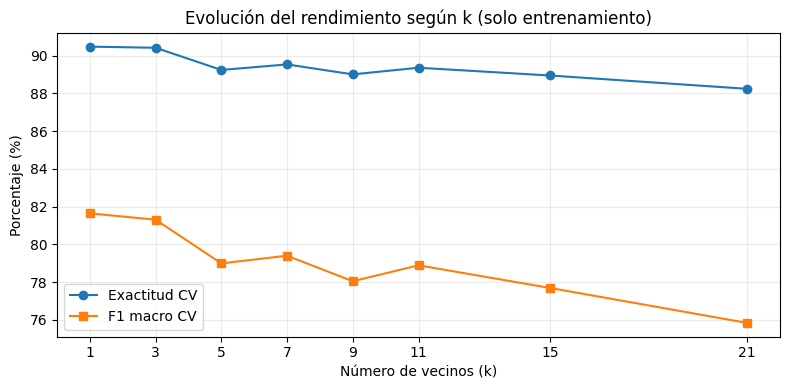

In [8]:
# Análisis de evolución del rendimiento al modificar el número de vecinos
plt.figure(figsize=(8, 4))
plt.plot(comparacion["k"], comparacion["Exactitud CV (%)"], marker="o", label="Exactitud CV")
plt.plot(comparacion["k"], comparacion["F1 macro CV (%)"], marker="s", label="F1 macro CV")
plt.xlabel("Número de vecinos (k)")
plt.ylabel("Porcentaje (%)")
plt.title("Evolución del rendimiento según k (solo entrenamiento)")
plt.xticks(k_values)
plt.grid(alpha=0.25)
plt.legend()
plt.tight_layout()
plt.show()

#### Análisis y conclusiones del modelo KNN

El modelo utiliza el clasificador `KNNClassifier` importado desde `Knn.py`, con una partición estratificada de 80% para entrenamiento y 20% para prueba (`seed=42`). Se parte de un dataset previamente limpio y se estandarizan las variables con estadísticas obtenidas exclusivamente de los datos de entrenamiento.

El valor de `k` se selecciona mediante validación cruzada de tres particiones utilizando el F1 macro. Los resultados efectivos de exactitud, F1 y matriz de confusión se muestran en las celdas anteriores al ejecutar el notebook.

**Nota:** El modelo se utiliza únicamente con fines académicos.


---

## Comparación final: KNN propio vs. Scikit-learn

Se comparan ambos clasificadores con **el mismo `k` seleccionado mediante validación cruzada**, las mismas muestras de prueba y los mismos datos estandarizados. Para la curva ROC multiclase se utiliza el enfoque **uno contra el resto (OvR)**. El KNN propio no implementa `predict_proba`, por lo que sus puntuaciones se obtienen externamente mediante la proporción de votos de los `k` vecinos más cercanos, sin modificar `Knn.py`.

Comparación con k = 1 y 425 muestras de prueba


,Accuracy (%),Precision macro (%),Recall macro (%),F1 macro (%)
Modelo,,,,
KNN propio,89.88,86.5,77.87,81.54
KNN sklearn,89.88,86.5,77.87,81.54


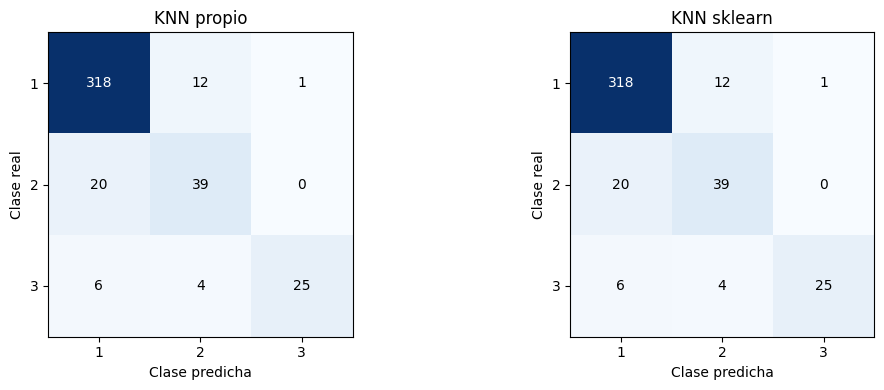

In [9]:
# Comparación con scikit-learn (sin volver a limpiar ni dividir el dataset)
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix as sk_confusion_matrix,
                             roc_curve, auc, roc_auc_score)

# Ambos modelos usan la misma distancia euclidiana y votación uniforme.
sklearn_knn = KNeighborsClassifier(n_neighbors=mejor_k, metric="euclidean", weights="uniform")
sklearn_knn.fit(X_train_scaled, y_train)
sklearn_preds = sklearn_knn.predict(X_test_scaled)

# Se reutilizan las predicciones del modelo propio calculadas anteriormente.
modelos_preds = {"KNN propio": test_preds, "KNN sklearn": sklearn_preds}
filas = []
for nombre, predicciones in modelos_preds.items():
    filas.append({
        "Modelo": nombre,
        "Accuracy (%)": 100 * accuracy_score(y_test, predicciones),
        "Precision macro (%)": 100 * precision_score(y_test, predicciones, labels=labels, average="macro", zero_division=0),
        "Recall macro (%)": 100 * recall_score(y_test, predicciones, labels=labels, average="macro", zero_division=0),
        "F1 macro (%)": 100 * f1_score(y_test, predicciones, labels=labels, average="macro", zero_division=0),
    })
comparacion_modelos = pd.DataFrame(filas).set_index("Modelo")
print(f"Comparación con k = {mejor_k} y {len(y_test)} muestras de prueba")
display(comparacion_modelos.round(2))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, (nombre, predicciones) in zip(axes, modelos_preds.items()):
    cm = sk_confusion_matrix(y_test, predicciones, labels=labels)
    ax.imshow(cm, cmap="Blues")
    ax.set_title(nombre)
    ax.set_xlabel("Clase predicha")
    ax.set_ylabel("Clase real")
    ax.set_xticks(range(len(labels)), [str(c) for c in labels])
    ax.set_yticks(range(len(labels)), [str(c) for c in labels])
    for (i, j), valor in np.ndenumerate(cm):
        ax.text(j, i, str(valor), ha="center", va="center", color="white" if valor > cm.max()/2 else "black")
plt.tight_layout()
plt.show()

### Curvas ROC multiclase (OvR)

Cada clase se evalúa frente a todas las demás. Se dibujan las curvas de ambos modelos y se compara el área bajo la curva (AUC). Las puntuaciones del modelo propio son **fracciones de votos**, no probabilidades calibradas.

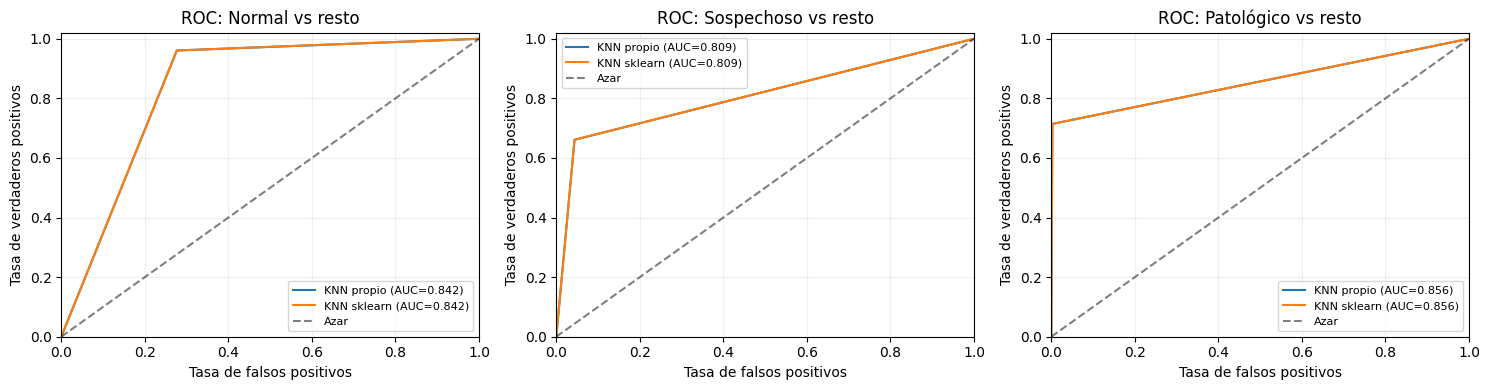

AUC por clase (uno contra el resto):


Modelo,KNN propio,KNN sklearn
Clase,,
Normal,0.8421,0.8421
Patológico,0.8559,0.8559
Sospechoso,0.8087,0.8087


Resumen del AUC multiclase:


,AUC macro OvR
Modelo,
KNN propio,0.8355
KNN sklearn,0.8355


Coincidencia de predicciones: 1.0
Diferencia máxima de puntuaciones: 0.0
Nota: si existen empates exactos en distancias, la elección de vecinos puede diferir entre implementaciones.


In [10]:
# Puntuaciones por clase del KNN propio, sin alterar el código de Knn.py.
# Equivalen a predict_proba de sklearn con weights="uniform".
def puntuaciones_knn_propio(modelo, X_nuevo, clases):
    puntuaciones = np.zeros((len(X_nuevo), len(clases)), dtype=float)
    for i, x in enumerate(X_nuevo):
        distancias = np.sqrt(np.sum((modelo.X_train - x) ** 2, axis=1))
        vecinos = np.argsort(distancias)[:modelo.k]
        etiquetas_vecinas = modelo.y_train[vecinos]
        for j, clase in enumerate(clases):
            puntuaciones[i, j] = np.mean(etiquetas_vecinas == clase)
    return puntuaciones

scores_propio = puntuaciones_knn_propio(knn_model, X_test_scaled, labels)
scores_sklearn = sklearn_knn.predict_proba(X_test_scaled)
# Asegurar que las columnas de sklearn sigan el mismo orden que labels.
scores_sklearn = scores_sklearn[:, [np.where(sklearn_knn.classes_ == c)[0][0] for c in labels]]

fig, axes = plt.subplots(1, len(labels), figsize=(5 * len(labels), 4))
auc_filas = []
for j, clase in enumerate(labels):
    y_binaria = (y_test == clase).astype(int)
    ax = axes[j]
    for nombre, scores in [("KNN propio", scores_propio), ("KNN sklearn", scores_sklearn)]:
        fpr, tpr, _ = roc_curve(y_binaria, scores[:, j])
        area = auc(fpr, tpr)
        auc_filas.append({"Clase": names.get(int(clase), str(clase)), "Modelo": nombre, "AUC": area})
        ax.plot(fpr, tpr, label=f"{nombre} (AUC={area:.3f})")
    ax.plot([0, 1], [0, 1], "k--", alpha=0.5, label="Azar")
    ax.set(title=f"ROC: {names.get(int(clase), str(clase))} vs resto", xlabel="Tasa de falsos positivos", ylabel="Tasa de verdaderos positivos", xlim=(0, 1), ylim=(0, 1.02))
    ax.legend(fontsize=8)
    ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()

auc_comparacion = pd.DataFrame(auc_filas).pivot(index="Clase", columns="Modelo", values="AUC")
print("AUC por clase (uno contra el resto):")
display(auc_comparacion.round(4))

resumen_auc = pd.DataFrame({
    "Modelo": ["KNN propio", "KNN sklearn"],
    "AUC macro OvR": [roc_auc_score(y_test, scores_propio, labels=labels, multi_class="ovr", average="macro"),
                      roc_auc_score(y_test, scores_sklearn, labels=labels, multi_class="ovr", average="macro")]
}).set_index("Modelo")
print("Resumen del AUC multiclase:")
display(resumen_auc.round(4))
print("Coincidencia de predicciones:", np.mean(test_preds == sklearn_preds))
print("Diferencia máxima de puntuaciones:", np.max(np.abs(scores_propio - scores_sklearn)))
print("Nota: si existen empates exactos en distancias, la elección de vecinos puede diferir entre implementaciones.")

### Interpretación de la comparación

- **Accuracy, Precision, Recall y F1 macro** permiten contrastar la calidad de las predicciones en el mismo conjunto de prueba.
- **ROC y AUC** comparan la capacidad de distinguir cada clase de las restantes a distintos umbrales. Un AUC cercano a 1 indica mejor discriminación; cerca de 0.5, un resultado similar al azar.
- Con los mismos vecinos y reglas de votación, los resultados deberían ser muy parecidos. Si existen distancias empatadas, las implementaciones pueden seleccionar vecinos diferentes.
- Esta comparación **no vuelve a entrenar ni modificar el KNN propio**: reutiliza `knn_model`, `test_preds`, `X_test_scaled` y `y_test` de las celdas anteriores.